# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [9]:
%%writefile heap.py
import matplotlib.pyplot as plt
import math

class Heap:

    def __init__(self):
        self.arreglo = [float('-inf')]

    # ── Sube el elemento en la posición i mientras sea menor que su padre
    def _sift_up(self, i):
        padre = i // 2
        while self.arreglo[i] < self.arreglo[padre]:
            self.arreglo[i], self.arreglo[padre] = self.arreglo[padre], self.arreglo[i]
            i = padre
            padre = i // 2

    # ── Baja el elemento en la posición i hacia su hijo mínimo
    def _sift_down(self, i):
        n = len(self.arreglo) - 1
        while 2 * i <= n:
            izq = 2 * i
            der = 2 * i + 1

            # elegir el hijo más pequeño
            if der <= n and self.arreglo[der] < self.arreglo[izq]:
                hijo_min = der
            else:
                hijo_min = izq

            # si ya está en su lugar, parar
            if self.arreglo[i] <= self.arreglo[hijo_min]:
                break

            self.arreglo[i], self.arreglo[hijo_min] = self.arreglo[hijo_min], self.arreglo[i]
            i = hijo_min
    def insert(self, valor, imagen=False):
        self.arreglo.append(valor)
        self._sift_up(len(self.arreglo) - 1)
        if imagen:
            self._mostrar_imagen()

    def remove_smallest(self, imagen=False):
        n = len(self.arreglo) - 1
        if n == 0:
            return None
        if n == 1:
            return self.arreglo.pop()
        minimo = self.arreglo[1]
        self.arreglo[1] = self.arreglo.pop()
        self._sift_down(1)
        if imagen:
            self._mostrar_imagen()
        return minimo

    def build_heap(self, lista, imagen=False):
        self.arreglo = [float('-inf')] + list(lista)
        ultimo_interno = (len(self.arreglo) - 1) // 2

        for i in range(ultimo_interno, 0, -1):
            self._sift_down(i)

        if imagen:
            self._mostrar_imagen()

    def _calcular_posiciones(self):
        n = len(self.arreglo) - 1

        # contar niveles sumando potencias de 2: nivel 0→1 nodo, nivel 1→2, nivel 2→4...
        niveles = 0
        while 2 ** niveles <= n:
            niveles += 1

        ancho = 2 ** (niveles - 1)
        pos = {}

        for i in range(1, n + 1):
            # encontrar en qué nivel está el nodo i
            nivel = 0
            while 2 ** (nivel + 1) <= i:
                nivel += 1

            pos_en_nivel = i - 2 ** nivel
            espaciado = ancho / 2 ** nivel
            x = (pos_en_nivel + 0.5) * espaciado
            y = niveles - nivel - 1
            pos[i] = (x, y)

        return pos, niveles

    def _mostrar_imagen(self):
        n = len(self.arreglo) - 1
        if n == 0:
            print("El heap está vacío.")
            return
        pos, niveles = self._calcular_posiciones()
        ancho_total = 2 ** (niveles - 1)
        radio = 0.35
        fig, ax = plt.subplots(figsize=(max(6, ancho_total + 1), max(4, niveles * 1.8)))
        ax.set_xlim(0, ancho_total)
        ax.set_ylim(-0.8, niveles - 0.2)
        ax.axis('off')
        for i in range(1, n + 1):
            x1, y1 = pos[i]
            for hijo in (2 * i, 2 * i + 1):
                if hijo <= n:
                    x2, y2 = pos[hijo]
                    ax.plot([x1, x2], [y1, y2], color='#555555', linewidth=1.5, zorder=1)
        for i in range(1, n + 1):
            x, y = pos[i]
            circulo = plt.Circle((x, y), radio, facecolor='#AED6F1',
                                  edgecolor='#2471A3', linewidth=2, zorder=2)
            ax.add_patch(circulo)
            ax.text(x, y, str(self.arreglo[i]),
                    ha='center', va='center', fontsize=11, fontweight='bold', zorder=3)
        plt.title(f"Min-Heap  ({n} nodo{'s' if n != 1 else ''})", fontsize=13)
        plt.tight_layout()
        plt.show()

Overwriting heap.py


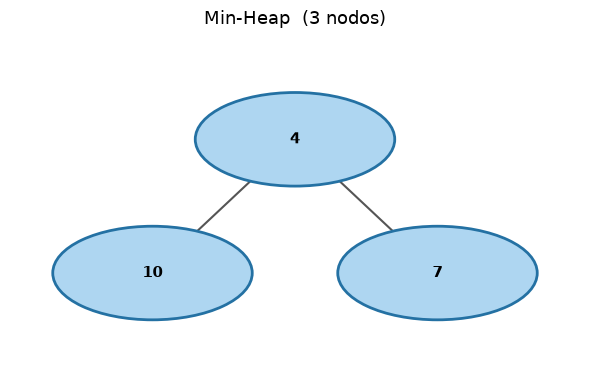

In [10]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)


## 6. Prueba: 5 inserciones con fotos

Todos hacen **la misma prueba**: empezando con un heap vacío, inserte **en este orden** los valores

```python
[15, 8, 20, 3, 10]
```

con `imagen=True` en cada inserción, y guarde las **5 imágenes** (una después de cada inserción) como archivos PNG en la carpeta `fotos`, dentro de `student_work/Proyecto2`:

```
student_work/Proyecto2/
├── heap.py
└── fotos/
    ├── insert_1.png    # después de insertar 15
    ├── insert_2.png    # después de insertar 8
    ├── insert_3.png    # después de insertar 20
    ├── insert_4.png    # después de insertar 3
    └── insert_5.png    # después de insertar 10
```

- Use exactamente esos nombres de archivo y esa carpeta.
- Cada foto muestra el árbol del heap **completo** después de esa inserción.
- No olvide hacer *commit* y *push* de la carpeta `fotos`.

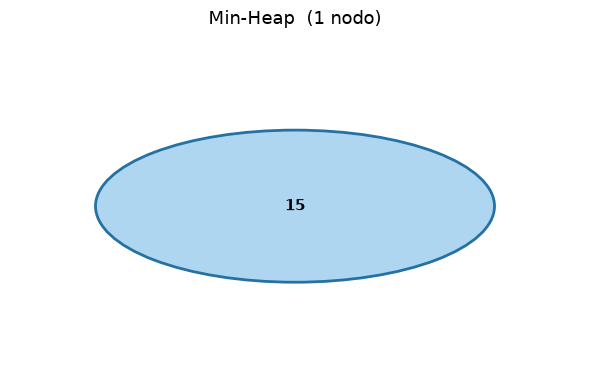

1 [-inf, 15]


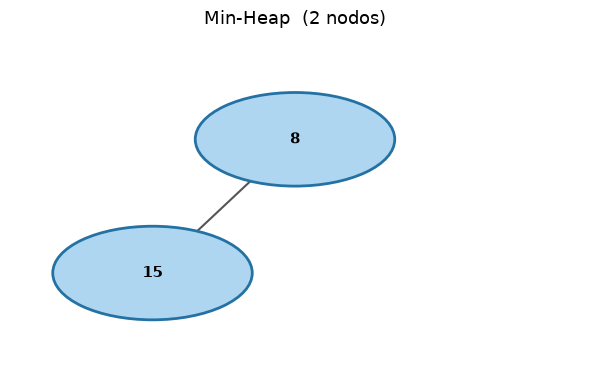

2 [-inf, 8, 15]


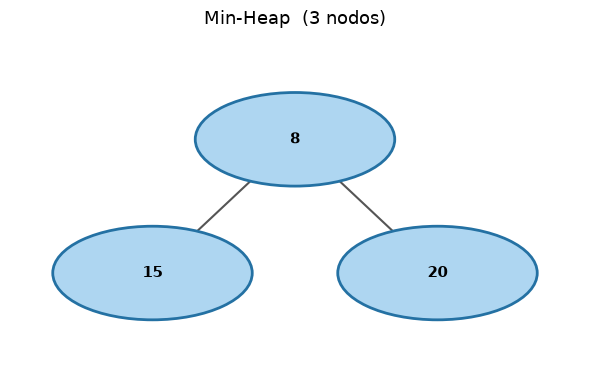

3 [-inf, 8, 15, 20]


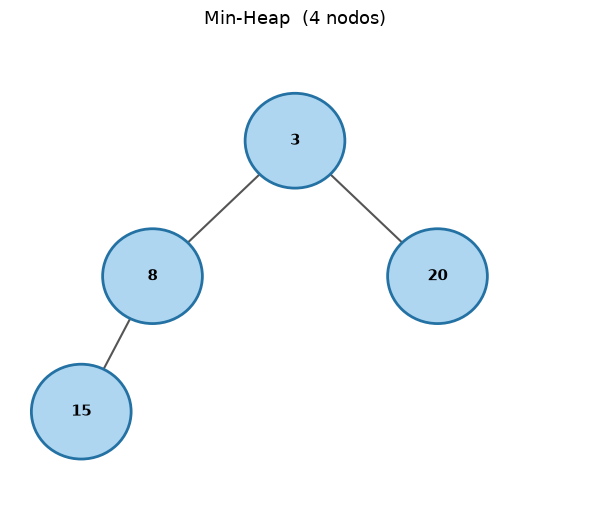

4 [-inf, 3, 8, 20, 15]


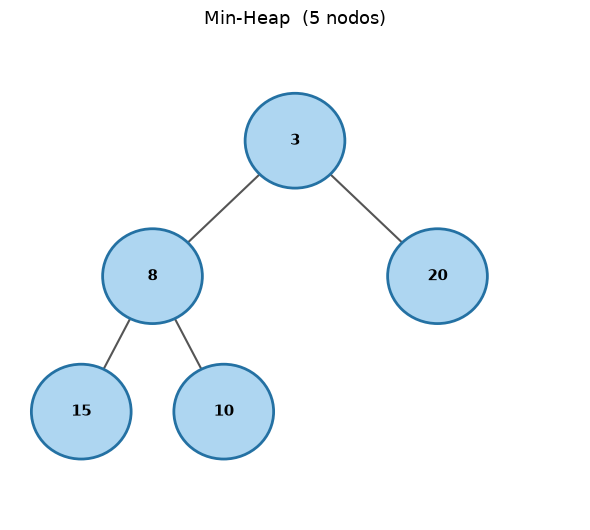

5 [-inf, 3, 8, 20, 15, 10]


In [11]:
import os
import importlib
import heap
importlib.reload(heap)
from heap import Heap

os.makedirs("fotos", exist_ok=True)     # crea la carpeta fotos si no existe

valores = [15, 8, 20, 3, 10]            # NO cambie esta lista

H = Heap()
for i, v in enumerate(valores, start=1):
    H.insert(v, imagen=True)
    # guarde aquí la imagen de esta inserción en f"fotos/insert_{i}.png"
    print(i, H.arreglo)